# Analyse sémantique

Dans ce notebook, nous allons explorer différentes méthodes de NLP pour choisir celle qui donne les meilleurs résultats :
- Bag of Words : 1 mot = 1 occurence
- TF-IDF : même principe, mais pondère les mots en fonction de leur rareté dans le corpus.
- N-2 : décompte les combinaisons de 2 mots (ex : très bien)
- ANNFIN : Donne un score émotionnel aux mots
- LDA : trouve les catégories.

https://regenerativetoday.com/countvectorizer-to-extract-features-from-texts-in-python-in-details/
https://towardsdatascience.com/basics-of-countvectorizer-e26677900f9c/
https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html
https://www.projectpro.io/recipes/use-count-vectorizer
https://stackoverflow.com/questions/44083683/countvectorizer-with-pandas-dataframe


In [33]:
import numpy as np, pandas as pd, os
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from afinn import Afinn
import matplotlib.pyplot as plt
import seaborn as sns


In [34]:
df = pd.read_csv('../0_Data/2_Clean/Traitement_intermediaire/data_preprocessed.csv')
df.head()

,avis,dates,series,allocine_id,review_id,plateforme,notes,notes_3,nb_capital_words,nb_exclamation_points,nb_exclamation_points_chains,nb_interrogation_points,nb_interrogation_points_chains,lenght,tokens,tokens_lemmatized
0,Honest Opinion - Turns out Westeros is way mor...,2026-01-24,A Knight of the Seven Kingdoms,28230,35604211,Imdb,8,1,0,0,0,0,0,419,honest opinion turns westeros way interesting ...,honest opinion turn westeros way interesting e...
1,"So Far, So Good (Don't Screw It Up) - The firs...",2026-01-19,A Knight of the Seven Kingdoms,28230,35604212,Imdb,9,1,1,0,0,0,0,638,far good screw first episode knight seven king...,far good screw first episode knight seven king...
2,A proper return to Westeros - I stayed up for ...,2026-01-19,A Knight of the Seven Kingdoms,28230,35604213,Imdb,9,1,1,0,0,0,0,1334,proper return westeros stayed 3 uk premiere on...,proper return westeros stayed 3 uk premiere on...
3,The only disappointment i had with ep 1 - Its ...,2026-01-19,A Knight of the Seven Kingdoms,28230,35604214,Imdb,9,1,0,1,0,1,0,404,disappointment ep 1 42 minuts expected hour ho...,disappointment ep 1 42 minuts expected hour ho...
4,Really freaking good with only one bad moment ...,2026-01-19,A Knight of the Seven Kingdoms,28230,35604215,Imdb,9,1,1,0,0,0,0,1964,really freaking good one bad moment far knight...,really freaking good one bad moment far knight...


In [35]:
# Identification des valeurs nulles
print(df.isna().sum())
df[df['tokens_lemmatized'].isna()]

avis                              0
dates                             0
series                            0
allocine_id                       0
review_id                         0
plateforme                        0
notes                             0
notes_3                           0
nb_capital_words                  0
nb_exclamation_points             0
nb_exclamation_points_chains      0
nb_interrogation_points           0
nb_interrogation_points_chains    0
lenght                            0
tokens                            2
tokens_lemmatized                 2
dtype: int64


,avis,dates,series,allocine_id,review_id,plateforme,notes,notes_3,nb_capital_words,nb_exclamation_points,nb_exclamation_points_chains,nb_interrogation_points,nb_interrogation_points_chains,lenght,tokens,tokens_lemmatized
329,👌 -,2026-02-07,A Knight of the Seven Kingdoms,28230,35604540,Imdb,10,1,0,0,0,0,0,4,NaN,NaN
766,"No, no, no, -",2026-02-23,A Knight of the Seven Kingdoms,28230,35604977,Imdb,8,1,0,0,0,0,0,14,NaN,NaN


In [36]:
# Suppression valeurs nulles et réinitialisation de l'index
df = df.dropna()
df = df.reset_index()

In [37]:
# Vectoriser en conservant les 100 mots les plus cités
vectorizer = CountVectorizer(max_features=100,
                             stop_words=['say', 'one', '10'])

count_matrix = vectorizer.fit_transform(df['tokens_lemmatized'])
print(count_matrix.shape)

(1410, 100)


In [38]:
count_array = count_matrix.toarray()

count_df = pd.DataFrame(data=count_array, columns=vectorizer.get_feature_names_out())
count_df.head()

,acting,action,actor,also,amazing,back,battle,best,better,book,...,watch,watching,way,well,westeros,without,work,world,would,writing
0,0,0,0,0,0,0,0,0,0,0,...,0,0,1,1,1,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
2,0,0,0,0,0,0,0,0,0,3,...,0,0,0,0,2,0,0,0,1,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,1,1,2,1,0,0,1,1,0


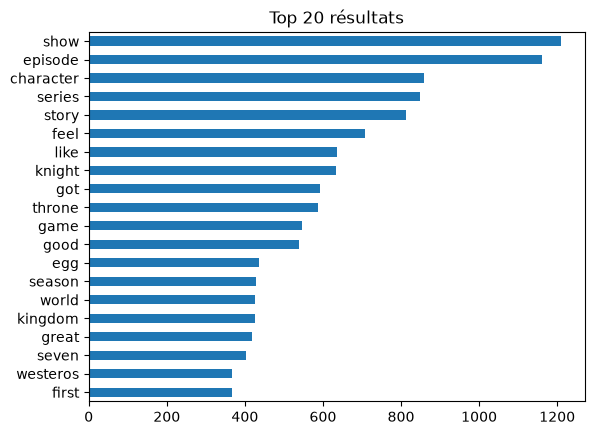

In [39]:
# Visualisation graphique des mots qui reviennent le plus souvent
top_n = 20
top_counts = count_df.sum(axis=0).sort_values(ascending=False).head(top_n)
top_counts.sort_values(ascending=True).plot(kind='barh')
plt.title(f"Top {top_n} résultats")
plt.show()

Cette méthode est intéressante mais nous laisse sur notre fin. Effectivement, 'show' et 'épisode' sont compréhensibles avec les mots qui suivent, alors que character ou story peuvent d'interpréter.

Nous essayerons donc la méthode TF-IDF puis des bigrames (combinaisons de 2 mots).

In [40]:
tfidf_vectorizer = TfidfVectorizer(max_features=100,
                             stop_words=['say', 'one', '10'],
                             norm=None) # Ne normalise pas les réponses

tfidf_matrix = tfidf_vectorizer.fit_transform(df['tokens_lemmatized'])

print(tfidf_matrix.shape)

(1410, 100)


In [41]:
tfidf_array = tfidf_matrix.toarray()

tfidf_df = pd.DataFrame(data=tfidf_array, columns=tfidf_vectorizer.get_feature_names_out())
tfidf_df.head()

,acting,action,actor,also,amazing,back,battle,best,better,book,...,watch,watching,way,well,westeros,without,work,world,would,writing
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,0.00000,2.881416,2.895468,2.783994,0.0,0.000000,0.000000,0.00000,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,0.00000,2.881416,0.000000,0.000000,0.0,3.533555,0.000000,0.00000,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.867628,...,0.0,0.00000,0.000000,0.000000,5.567988,0.0,0.000000,0.000000,3.12809,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,0.00000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.00000,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,2.96885,2.881416,5.790935,2.783994,0.0,0.000000,2.585627,3.12809,0.0


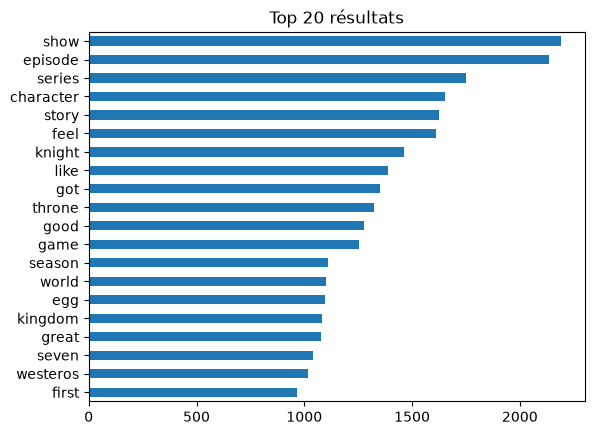

In [42]:
# Visualisation des mots qui reviennent le plus.
top_n = 20
top_tfidf = tfidf_df.sum(axis=0).sort_values(ascending=False).head(top_n)
top_tfidf.sort_values(ascending=True).plot(kind='barh')
plt.title(f"Top {top_n} résultats")
plt.show()

## Ngrams

(1410, 100)


,30 minute,absolute cinema,amazing show,best series,best show,breath fresh,character development,character driven,character feel,dexter sol,...,true knight,tv show,two episode,wait see,waste time,well done,well written,world building,world feel,world westeros
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0


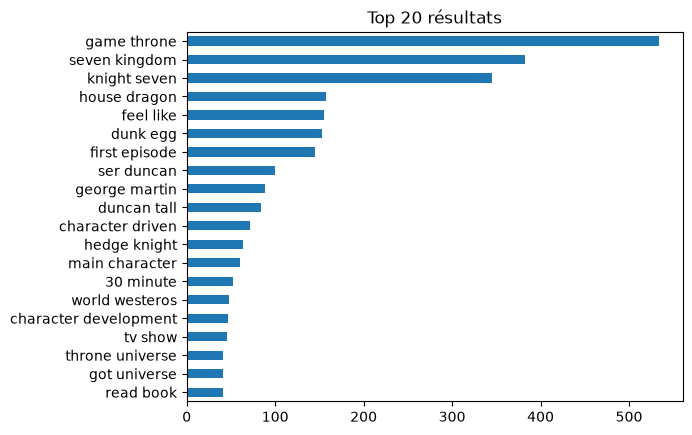

In [43]:
# Commençons de le tester avec le count vectorizer
vectorizer_bigrams = CountVectorizer(max_features=100,
                             stop_words=['say', 'one', '10'],
                             ngram_range=(2,2))

bigrams_count_matrix = vectorizer_bigrams.fit_transform(df['tokens_lemmatized'])
print(bigrams_count_matrix.shape)

bigrams_array = bigrams_count_matrix.toarray()
bigrams_df = pd.DataFrame(data=bigrams_array, columns=vectorizer_bigrams.get_feature_names_out())
display(bigrams_df.head())

top_n = 20
top_bigrams = bigrams_df.sum(axis=0).sort_values(ascending=False).head(top_n)
top_bigrams.sort_values(ascending=True).plot(kind='barh')
plt.title(f"Top {top_n} résultats")
plt.show()


(1410, 100)


,30 minute,absolute cinema,amazing show,best series,best show,breath fresh,character development,character driven,character feel,dexter sol,...,true knight,tv show,two episode,wait see,waste time,well done,well written,world building,world feel,world westeros
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,5.033178,0.0,0.0,0.0


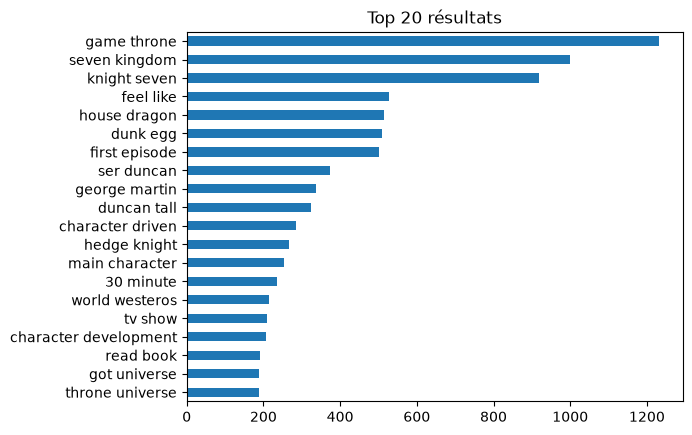

In [44]:
# Essayons maintenant les bigrams avec le tf-idf.
tfidf_bigrams = TfidfVectorizer(max_features=100,
                             stop_words=['say', 'one', '10'],
                             norm=None,
                             ngram_range=(2,2))

bigrams_tfidf_matrix = tfidf_bigrams.fit_transform(df['tokens_lemmatized'])
print(bigrams_tfidf_matrix.shape)

tfidf_bigrams_array = bigrams_tfidf_matrix.toarray()
tfidf_bigrams_df = pd.DataFrame(data=tfidf_bigrams_array, columns=tfidf_bigrams.get_feature_names_out())
display(tfidf_bigrams_df.head())

top_n = 20
top_tfids = tfidf_bigrams_df.sum(axis=0).sort_values(ascending=False).head(top_n)
top_tfids.sort_values(ascending=True).plot(kind='barh')
plt.title(f"Top {top_n} résultats")
plt.show()

Le TF-IDF ne semble pas réellement apporter d'amélioration au Bag of Words avec les N-grams.

Par facilité d'interprétation, nous conservons les bigrams en Bag of Words.

Avant de rentrer dans l'analyse par série et par note, rentrons testons :
- l'AFINN, qui donne un score de sentiment par phrase
- La LDA, qui thématise les verbatims. 

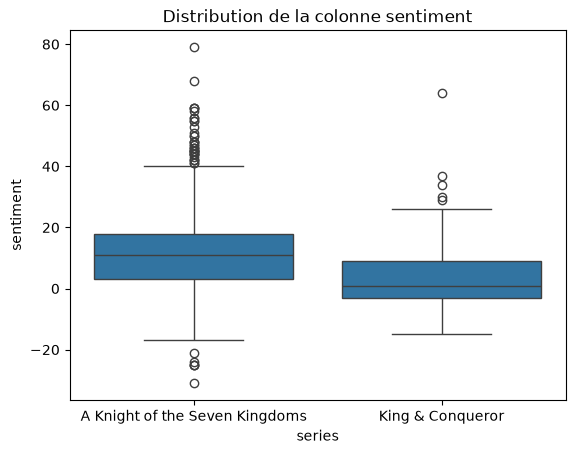

In [45]:
# Instanciation
afn = Afinn()

# Création de la colonne avec afn.score
df['sentiment'] = df['tokens_lemmatized'].map(afn.score)

# Regardons la distribution du score de sentiments (méthode Afinn)
sns.boxplot(x=df["series"], y=df['sentiment'])
plt.title('Distribution de la colonne sentiment')
plt.show()


In [46]:
df.groupby('series')['sentiment'].median()

series
A Knight of the Seven Kingdoms    11.0
King & Conqueror                   1.0
Name: sentiment, dtype: float64

In [47]:
# Enregistrement des données avec le score de sentiment
# Export en csv
# Un point = dossier actuel, deux points = dossier parent

output_path = '../0_Data/2_Clean/data_preprocessed_final.csv'
os.makedirs(os.path.dirname(output_path), exist_ok=True)
df.to_csv(output_path, index=False)

Les résultats de l'Afinn ont l'air prometteurs ! Avant de rentrer dans l'analyse, regardons ce que donne le LDA (Latent Ditriech Allocation).

Doc : https://medium.com/data-science/end-to-end-topic-modeling-in-python-latent-dirichlet-allocation-lda-35ce4ed6b3e0

https://larevueia.fr/latent-dirichlet-allocation-topic-modeling-en-python/

https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.LatentDirichletAllocation.html





In [48]:
from sklearn.decomposition import LatentDirichletAllocation

# Nombre de thématiques
n_topics = 8

# Instanciation et entrainement
lda = LatentDirichletAllocation(
    n_components=n_topics,
    max_iter=20,
    learning_method='online',
    random_state=42,
    n_jobs=-1
)

# Entrainement du modèle
lda.fit(bigrams_tfidf_matrix)


,"n_components n_components: int, default=10Number of topics... versionchanged:: 0.19 ``n_topics`` was renamed to ``n_components``",8
,"learning_method learning_method: {'batch', 'online'}, default='batch'Method used to update `_component`. Only used in :meth:`fit` method.In general, if the data size is large, the online update will be muchfaster than the batch update.Valid options:- 'batch': Batch variational Bayes method. Use all training data in each EM update. Old `components_` will be overwritten in each iteration.- 'online': Online variational Bayes method. In each EM update, use mini-batch of training data to update the ``components_`` variable incrementally. The learning rate is controlled by the ``learning_decay`` and the ``learning_offset`` parameters... versionchanged:: 0.20 The default learning method is now ``""batch""``.",'online'
,"max_iter max_iter: int, default=10The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the :meth:`fit` method, and not the:meth:`partial_fit` method.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use in the E-step.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NonePass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"doc_topic_prior doc_topic_prior: float, default=NonePrior of document topic distribution `theta`. If the value is None,defaults to `1 / n_components`.In [1]_, this is called `alpha`.",None
,"topic_word_prior topic_word_prior: float, default=NonePrior of topic word distribution `beta`. If the value is None, defaultsto `1 / n_components`.In [1]_, this is called `eta`.",None
,"learning_decay learning_decay: float, default=0.7It is a parameter that control learning rate in the online learningmethod. The value should be set between (0.5, 1.0] to guaranteeasymptotic convergence. When the value is 0.0 and batch_size is``n_samples``, the update method is same as batch learning. In theliterature, this is called kappa.",0.7
,"learning_offset learning_offset: float, default=10.0A (positive) parameter that downweights early iterations in onlinelearning. It should be greater than 1.0. In the literature, this iscalled tau_0.",10.0
,"batch_size batch_size: int, default=128Number of documents to use in each EM iteration. Only used in onlinelearning.",128
,"evaluate_every evaluate_every: int, default=-1How often to evaluate perplexity. Only used in `fit` method.set it to 0 or negative number to not evaluate perplexity intraining at all. Evaluating perplexity can help you check convergencein training process, but it will also increase total training time.Evaluating perplexity in every iteration might increase training timeup to two-fold.",-1


In [49]:
# Afficher les mots-clé par topics
feature_names = tfidf_bigrams.get_feature_names_out()
n_top_words = 10

for topic_idx, topic in enumerate(lda.components_):
    top_words = [feature_names[i] for i in topic.argsort()[-n_top_words:][::-1]]
    print(f"Topic #{topic_idx+1}: {', '.join(top_words)}")

# Assigner le topic dominant à chaque commentaire
topic_matrix = lda.transform(bigrams_tfidf_matrix)
df['dominant_topic'] = topic_matrix.argmax(axis=1)
df['topic_confidence'] = topic_matrix.max(axis=1)      # Probabilité du topic dominant

Topic #1: ser duncan, duncan tall, seven kingdom, knight seven, game throne, world westeros, must watch, world building, character driven, first season
Topic #2: feel like, dunk egg, 30 minute, absolute cinema, well written, story feel, world feel, massive battle, like show, kingdom feel
Topic #3: seven kingdom, knight seven, hedge knight, game throne, george martin, look like, ice fire, house dragon, song ice, return westeros
Topic #4: game throne, episode short, peter claffey, source material, fresh air, breath fresh, dexter sol, sol ansell, felt like, like got
Topic #5: house dragon, main character, read book, got universe, short episode, great show, game throne, throne house, show feel, feel personal
Topic #6: throne universe, best show, good show, every episode, feel real, every scene, duncan egg, show ever, next season, love show
Topic #7: first episode, tv show, looking forward, character development, next episode, best series, game throne, minute episode, got hotd, long time
To

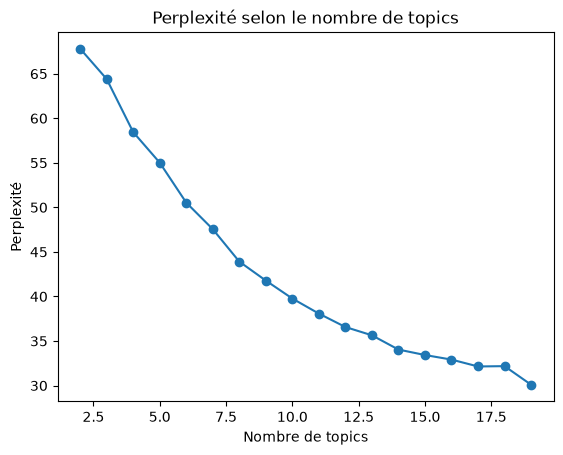

In [50]:
# Je trouve que les topics sont trop proches entre eux.
# Testons la méthode du coude pour choisir le nombre de topics.

perplexities = []
topic_range = range(2, 20)

for n in topic_range:
    lda_test = LatentDirichletAllocation(n_components=n, random_state=42, learning_method='online')
    lda_test.fit(bigrams_tfidf_matrix)
    perplexities.append(lda_test.perplexity(bigrams_tfidf_matrix))

plt.plot(topic_range, perplexities, marker='o')
plt.xlabel('Nombre de topics')
plt.ylabel('Perplexité')
plt.title('Perplexité selon le nombre de topics')
plt.show()

In [ ]:
# 8 et 13 semblent être deux points de rupture.

# Essai avec le count vectorizer
vectorizer = CountVectorizer(
    max_df=0.90,          # filtre les termes trop fréquents
    min_df=10,            # filtre les bigrammes rares (crucial)
    max_features=8000     # max de mots pour éviter l'explosion
)

cnt = vectorizer.fit_transform(df['tokens_lemmatized'])

# Instanciation et entrainement
lda = LatentDirichletAllocation(
    n_components=n_topics,
    max_iter=20,
    learning_method='online',
    random_state=42,
    n_jobs=-1
)

perplexities = []
topic_range = range(2, 20)

for n in topic_range:
    lda = LatentDirichletAllocation(n_components=n, random_state=42, learning_method='online')
    lda.fit(cnt)
    perplexities.append(lda.perplexity(cnt))

plt.plot(topic_range, perplexities, marker='o')
plt.xlabel('Nombre de topics')
plt.ylabel('Perplexité')
plt.title('Perplexité selon le nombre de topics')
plt.show()

In [ ]:
# Nombre de thématiques
n_topics = 13

# Instanciation et entrainement
lda = LatentDirichletAllocation(
    n_components=n_topics,
    max_iter=20,
    learning_method='online',
    random_state=42,
    n_jobs=-1
)

# Entrainement du modèle
lda.fit(cnt)

# Afficher les mots-clé par topics
feature_names = vectorizer.get_feature_names_out()
n_top_words = 10

for topic_idx, topic in enumerate(lda.components_):
    top_words = [feature_names[i] for i in topic.argsort()[-n_top_words:][::-1]]
    print(f"Topic #{topic_idx+1}: {', '.join(top_words)}")

# Assigner le topic dominant à chaque commentaire
topic_matrix = lda.transform(cnt)
df['dominant_topic'] = topic_matrix.argmax(axis=1)
df['topic_confidence'] = topic_matrix.max(axis=1)      # Probabilité du topic dominant

Topic #1: william, england, historical, king, harold, battle, period, 1066, norman, normandy
Topic #2: break, function, 15, bodily, involved, substance, unnecessary, live, writing, person
Topic #3: awful, best, bad, shot, rubbish, utter, meaning, worse, root, actually
Topic #4: fresh, air, breath, dexter, peter, ansell, claffey, good, sol, universe
Topic #5: book, read, adaptation, faithful, work, source, already, loved, casting, original
Topic #6: knight, kingdom, seven, westeros, world, feel, story, series, egg, throne
Topic #7: show, episode, got, good, season, series, character, great, story, game
Topic #8: historical, inaccuracy, understand, take, bbc, story, shame, looked, conqueror, mess
Topic #9: timeline, night, finally, amazing, solid, hope, begin, pilot, anymore, overall
Topic #10: feel, every, character, 10, storytelling, scene, episode, pacing, moment, emotional
Topic #11: wonderful, fire, episode, ice, min, song, world, akotsk, please, start
Topic #12: dont, im, ira, grrm

Le LDA donne des thématiques intéressantes en utilisant le count vectorizer, mais ce n'est pas la méthode que je vais retenir pour mon analyse, car pas la plus facile à interpréter.

Je vais privilégier le TOP20 des bigrames avec le count vectorizer par série et par catégorie de notes, pour connaître facilement les raisons derrière les notes mises.

Principaux bigrames de la série : A Knight of the Seven Kingdoms

Note analysée : 1
Nombre de commentaires : 1015
Score de sentiments de la note 1 de la série A Knight of the Seven Kingdoms :  14.09


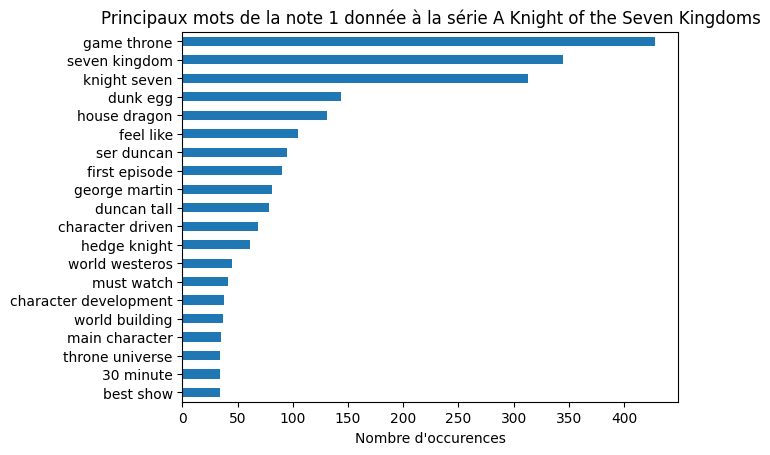


Note analysée : 0
Nombre de commentaires : 95
Score de sentiments de la note 0 de la série A Knight of the Seven Kingdoms :  5.65


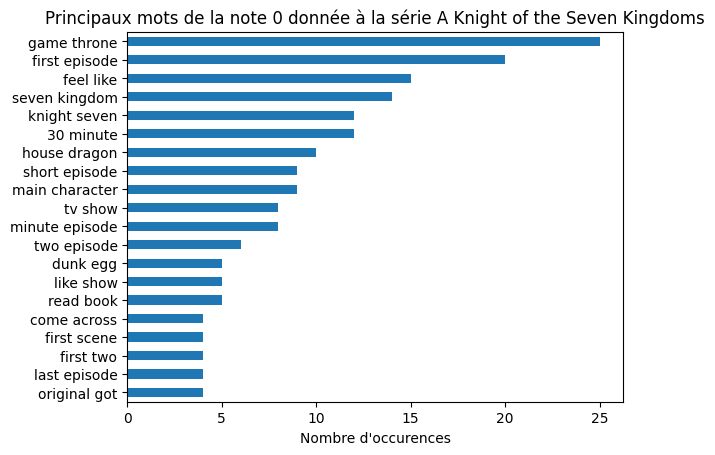


Note analysée : -1
Nombre de commentaires : 127
Score de sentiments de la note -1 de la série A Knight of the Seven Kingdoms :  -0.54


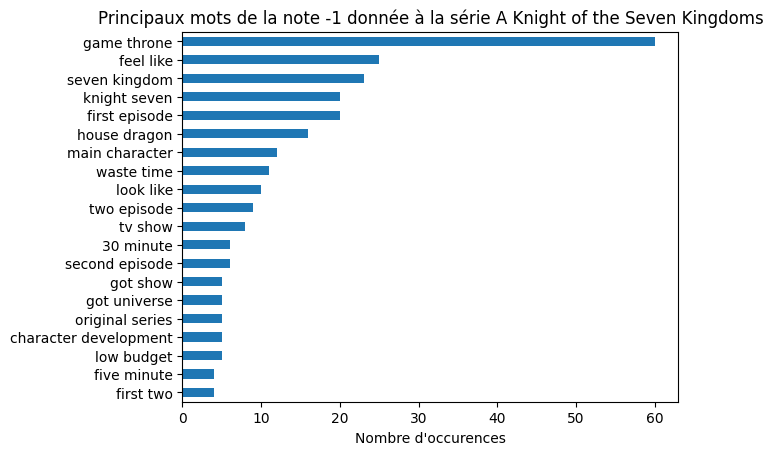

Principaux bigrames de la série : King & Conqueror

Note analysée : 1
Nombre de commentaires : 50
Score de sentiments de la note 1 de la série King & Conqueror :  12.04


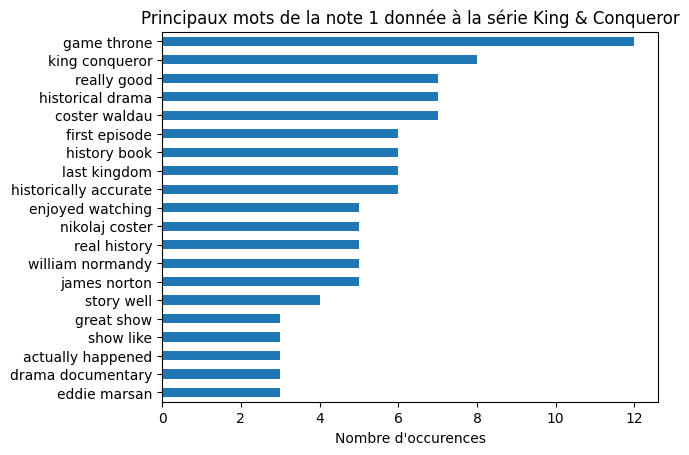


Note analysée : 0
Nombre de commentaires : 42
Score de sentiments de la note 0 de la série King & Conqueror :  3.07


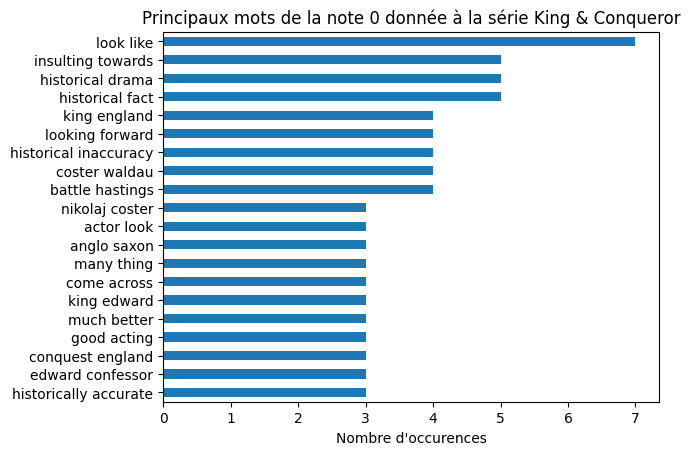


Note analysée : -1
Nombre de commentaires : 81
Score de sentiments de la note -1 de la série King & Conqueror :  -2.58


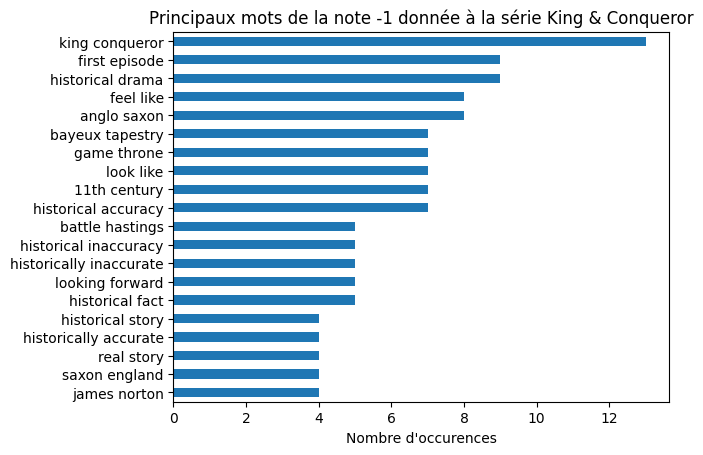

In [ ]:
for serie in df['series'].unique():

    print(f"Principaux bigrames de la série : {serie}")

    # Création df
    df_serie = df[df['series'] == serie]

    for note in df['notes_3'].unique():
        print()
        print(f"Note analysée : {note}")

        # Création df
        df_serie_note = df_serie[df_serie['notes_3'] == note].reset_index()
        print("Nombre de commentaires :", len(df_serie_note))


        # Editer les bigrames avec le count vectorizer
        max_bigrams = 100
        vectorizer_bigrams = CountVectorizer(max_features=max_bigrams,
                                stop_words=['say', 'one', '10'],
                                ngram_range=(2,2))

        bigrams_count_matrix = vectorizer_bigrams.fit_transform(df_serie_note['tokens_lemmatized'])
        bigrams_array = bigrams_count_matrix.toarray()
        
        # Créer un nouveau df avec les bigrams
        bigrams_cols = vectorizer_bigrams.get_feature_names_out()
        bigrams_df = pd.DataFrame(data=bigrams_array, columns=bigrams_cols)

        # Concaténation sur la base de l'index
        df_serie_note = df_serie_note.join(bigrams_df)
        
        # Afficher le score sentimental moyen
        score_sentiment_moyen = df_serie_note['sentiment'].mean()
        print(f"Score de sentiments de la note {note} de la série {serie} : ", \
              round(score_sentiment_moyen, 2))

        # Afficher le topX des mots
        top_n = 20
        top_bigrams = df_serie_note[bigrams_cols].sum(axis=0).sort_values(ascending=False).head(top_n)

        top_bigrams.sort_values(ascending=True).plot(kind='barh')
        plt.xlabel("Nombre d'occurences")
        plt.title(f'Principaux mots de la note {note} donnée à la série {serie}')
        plt.show()

### Analyse :

## A Knight of the Seven Kingdoms :
- Les verbatims positifs mettent en avant les personnages principaux, et leur développement tout au long de la série.
- Au contraire, les verbatims négatifs parlent également des personnages principaux, des deux premiers épisodes, du format d'épisodes courts (30 minutes), et du budget qui semble faible pour une série de l'univers de Game of Thrones.

Mes recommandations pour la prochaine saison : continuer sur cette lancée en se concentrant sur le développement des deux personnages. 

## King & Conqueror :
- Les commentaires positifs parlent également de Game of Throne : les spectateurs sont probablement attirés par la ressemblence avec l'univers. Les acteurs Nikolaj Coster Waldau, qui joue Jamie Lannister, et James Norton sont mis en avant. Les spectateurs apprécient l'aspect historique de la série, qu'ils jugent précis, presque à la manière d'un documentaire.
- Au contraire, les commentaires négatifs remettent fortement en cause la véricité historique de la série. Le premier épisode revient particulièrement dans les commentaires.

Mes recommandations pour la prochaine saison : essayer de se rapprocher davantage des faits historiques. Si des simplifications doivent être effectuées, que ce soit fait en cohérence avec les personnages historiques.

## Export pour que ce soit exploitable dans PowerBI

Il faut que je connecte l'analyse sémantique du NLP dans un futur modèle PowerBI. J'aimerais que ce soit dans une table séparée qui se connecterait avec les réponses.

Plusieurs options s'offrent à moi :
1. Faire un grand df avec les bigrames de toutes les séries réunies.
2. Faire un df par série, donc un modèle différencié par série.

L'option 1 serait plus facile dans le cadre de la création d'une grande BDD, mais il faudrait reprendre un grand nombre de bigrams pour avoir des résultat sur les séries avec peu de commentaires.

L'option 2 serait adéquate pour une analyse série par série mais il faudrait multiplier les tables si l'on devait créer une BDD.

Sachant que mon but ici est de créer un dashboard interactif avec les principales informations sur les séries.

Finalement, une 3ème solution a émergé grâce à mes échanges avec Claude. Il est possible de créer une table avec trois colonnes (review_id, bigram, count), qui renvoie le compte des bigrams par verbatim : https://claude.ai/share/2fc1dcef-42b6-4990-a9c6-ea85d40cc357

C'est une solution plus simple pour l'exploitation dans PowerBI, et pour la mise en échelle. 

Pour ce faire, je suis parti créer un review_id unique par série et par commentaire.

In [ ]:
# Création de la table bigrams.

records = []

for serie in df['series'].unique():
    df_serie = df[df['series'] == serie].copy()

    # Faire un décompte des bigrams par série.
    vectorizer = CountVectorizer(
        max_features=500,
        stop_words=['say', 'one', '10'],
        ngram_range=(2,2)
    )

    matrix = vectorizer.fit_transform(df_serie['tokens_lemmatized'])
    bigrams_cols = vectorizer.get_feature_names_out()

    # Création d'une ligne (records) pour chaque bigram
    for i, row in enumerate(matrix.toarray()):
        review_id = df_serie['review_id'].iloc[i]

        for bigram, count in zip(bigrams_cols, row):
            if count > 0:            # Retirer les lignes avec les 0 pour alléger la table.
                records.append({
                    'review_id' : review_id,
                    'bigram' : bigram,
                    'count' : count
                })

df_bigrams = pd.DataFrame(records)

# Export en csv
# Un point = dossier actuel, deux points = dossier parent
output_path = '../0_Data/2_Clean/bigrams.csv'
os.makedirs(os.path.dirname(output_path), exist_ok=True)
df_bigrams.to_csv(output_path, index=False)

In [ ]:
# Prochaine étape : travailler sur la réorganisation du dossier.
# Puis initier le PowerBI.
# Puis travailler sur du SQL.